In [1]:
# Cell 1: Imports

import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

from dreams.api import PreTrainedModel
from dreams.models.dreams.dreams import DreaMS as DreaMSModel
from dreams.utils.data import SpectrumPreprocessor
from dreams.utils.dformats import DataFormatA

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), (
    "CUDA is not available. This experiment is intended to run on the GPU machine."
)

device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))


C:\Users\892hf\miniforge3\envs\dreams\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.2.1+cu121
CUDA available: True
GPU: NVIDIA GeForce RTX 4080


In [2]:

# Cell 2: Paths and experiment configuration

DATA_DIR = Path("model_datasets/stage_1_5pct")

TRAIN_PATH = DATA_DIR / "train.parquet"
VALIDATION_PATH = DATA_DIR / "validation.parquet"
CLASS_MAPPING_PATH = DATA_DIR / "class_mapping.json"
EXPERIMENT_CONFIG_PATH = DATA_DIR / "experiment_config.json"

# Your existing pretrained DreaMS checkpoint
DREAMS_CHECKPOINT = Path(r"D:\Data Science Toolbox\Group Sprints\Sprint 2\gpu_run_package\DreaMS_project\ssl_model.ckpt")

# Output directory for this experiment
OUTPUT_DIR = Path("results/fine_tuned_dreams_experiment_2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Reproducibility
SEED = 42

# DreaMS preprocessing
N_HIGHEST_PEAKS = 60
PRECURSOR_INTENSITY = 1.1

# Training configuration
BATCH_SIZE = 32
MAX_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5

ENCODER_LR = 1e-5
CLASSIFIER_LR = 3e-4
WEIGHT_DECAY = 0.01
DROPOUT = 0.3

import os  # added by run_gpu_jobs.py
NUM_WORKERS = 0 if os.name == "nt" else 4  # Windows: DataLoader workers can't import classes defined in a notebook

# Use the same class mapping as the frozen experiment
print("Training data:", TRAIN_PATH)
print("Validation data:", VALIDATION_PATH)
print("Checkpoint:", DREAMS_CHECKPOINT)
print("Output directory:", OUTPUT_DIR)


Training data: model_datasets\stage_1_5pct\train.parquet
Validation data: model_datasets\stage_1_5pct\validation.parquet
Checkpoint: D:\Data Science Toolbox\Group Sprints\Sprint 2\gpu_run_package\DreaMS_project\ssl_model.ckpt
Output directory: results\fine_tuned_dreams_experiment_2


In [3]:

# Cell 3: Check input files

required_files = [
    TRAIN_PATH,
    VALIDATION_PATH,
    CLASS_MAPPING_PATH,
    DREAMS_CHECKPOINT
]

for path in required_files:
    assert path.exists(), f"Missing file: {path.resolve()}"
    print(f"Found: {path}")


Found: model_datasets\stage_1_5pct\train.parquet
Found: model_datasets\stage_1_5pct\validation.parquet
Found: model_datasets\stage_1_5pct\class_mapping.json
Found: D:\Data Science Toolbox\Group Sprints\Sprint 2\gpu_run_package\DreaMS_project\ssl_model.ckpt


In [4]:

# Cell 4: Load data

train_df = pd.read_parquet(TRAIN_PATH)
validation_df = pd.read_parquet(VALIDATION_PATH)

# Added by run_gpu_jobs.py, as in the frozen experiment (Michael's email, 22 Nov): keep only the
# validation spectra whose molecule is in training; class_mapping.json covers training molecules only.
training_molecules = set(train_df["inchikey14"].dropna().unique())
validation_df_original = validation_df
validation_df = validation_df[validation_df["inchikey14"].isin(training_molecules)].copy()
print(f"Validation spectra kept (molecule in training): {len(validation_df):,} of {len(validation_df_original):,}")


print("Training spectra:", len(train_df))
print("Validation spectra:", len(validation_df))

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nValidation columns:")
print(validation_df.columns.tolist())

assert "inchikey14" in train_df.columns
assert "inchikey14" in validation_df.columns

assert "mzs" in train_df.columns
assert "intensities" in train_df.columns
assert "precursor_mz" in train_df.columns

assert train_df["inchikey14"].notna().all()
assert validation_df["inchikey14"].notna().all()


Validation spectra kept (molecule in training): 10,153 of 22,963
Training spectra: 91851
Validation spectra: 10153

Training columns:
['row_id', 'inchikey14', 'ingest_lib', 'group', 'instrument_family', 'ionization_mode', 'adduct', 'charge', 'is_dimer', 'precursor_mz', 'ppm_error', 'collision_energy_ev', 'collision_energy_orig_units', 'n_peaks', 'mzs', 'intensities', 'bins', 'bin_intensities', 'source_part']

Validation columns:
['row_id', 'inchikey14', 'ingest_lib', 'group', 'instrument_family', 'ionization_mode', 'adduct', 'charge', 'is_dimer', 'precursor_mz', 'ppm_error', 'collision_energy_ev', 'collision_energy_orig_units', 'n_peaks', 'mzs', 'intensities', 'bins', 'bin_intensities', 'source_part']


In [5]:

# Cell 5: Load class mapping

with open(CLASS_MAPPING_PATH, "r") as f:
    mapping_data = json.load(f)


def extract_class_mapping(data):

    # Handle common dictionary structures
    if isinstance(data, dict):

        for key in ["class_to_idx", "class_mapping"]:
            if key in data and isinstance(data[key], dict):
                data = data[key]
                break

        # Label -> integer index
        if isinstance(data, dict):
            if all(isinstance(v, int) for v in data.values()):
                return {str(k): int(v) for k, v in data.items()}

            # Integer index -> label
            if all(str(k).isdigit() for k in data.keys()):
                return {str(v): int(k) for k, v in data.items()}

        # A list of class labels
        if isinstance(data, dict) and "classes" in data:
            classes = data["classes"]
            if isinstance(classes, list):
                return {str(label): i for i, label in enumerate(classes)}

    # A list of class labels at the top level
    if isinstance(data, list):
        return {str(label): i for i, label in enumerate(data)}

    raise ValueError(
        "Could not identify the class-to-index mapping. "
        "Please inspect class_mapping.json."
    )


class_to_idx = extract_class_mapping(mapping_data)

NUM_CLASSES = len(class_to_idx)

assert sorted(class_to_idx.values()) == list(range(NUM_CLASSES))

print("Number of classes:", NUM_CLASSES)
print("First five mapping entries:")
print(list(class_to_idx.items())[:5])


Number of classes: 65644
First five mapping entries:
[('AAAJHMPMZMRLLC', 0), ('AAAQFGUYHFJNHI', 1), ('AABFPLCJKGQASP', 2), ('AABIGZKMCHNPNA', 3), ('AABILZKQMVKFHP', 4)]


In [6]:

# Cell 6: Check labels

train_df["inchikey14"] = train_df["inchikey14"].astype(str)
validation_df["inchikey14"] = validation_df["inchikey14"].astype(str)

unknown_validation_labels = (
    set(validation_df["inchikey14"]) - set(class_to_idx)
)

print("Training classes:", len(set(train_df["inchikey14"])))
print("Validation classes:", len(set(validation_df["inchikey14"])))
print("Validation-only classes:", len(unknown_validation_labels))

assert set(train_df["inchikey14"]).issubset(class_to_idx)

assert len(unknown_validation_labels) == 0, (
    "Some validation labels are not present in the training class mapping."
)

train_df["label"] = train_df["inchikey14"].map(class_to_idx)
validation_df["label"] = validation_df["inchikey14"].map(class_to_idx)

train_df["label"] = train_df["label"].astype(np.int64)
validation_df["label"] = validation_df["label"].astype(np.int64)

assert train_df["label"].min() >= 0
assert train_df["label"].max() < NUM_CLASSES

print("Label mapping checks passed.")


Training classes: 65644
Validation classes: 7786
Validation-only classes: 0
Label mapping checks passed.


In [7]:

# Cell 7: Initialise DreaMS preprocessing

dformat = DataFormatA()

spec_preproc = SpectrumPreprocessor(
    dformat=dformat,
    prec_intens=PRECURSOR_INTENSITY,
    n_highest_peaks=N_HIGHEST_PEAKS,
    normalize_mzs=False,
    precision=32,
    to_relative_intensities=True
)

print("DreaMS spectrum preprocessor initialised.")


DreaMS spectrum preprocessor initialised.


In [8]:

# Cell 8: Convert spectra into DreaMS input tensors

def preprocess_dataframe(df, dataset_name):

    processed_spectra = []

    for i, row in enumerate(df.itertuples(index=False)):

        mzs = np.asarray(row.mzs, dtype=np.float32)
        intensities = np.asarray(row.intensities, dtype=np.float32)
        precursor_mz = float(row.precursor_mz)

        assert len(mzs) == len(intensities), (
            f"Mismatched peak arrays in {dataset_name}, row {i}"
        )

        assert len(mzs) > 0, (
            f"Empty spectrum in {dataset_name}, row {i}"
        )

        spectrum = np.vstack([mzs, intensities])

        processed = spec_preproc(
            spectrum,
            precursor_mz,
            high_form=False,
            augment=False
        )

        processed = np.asarray(processed, dtype=np.float32)

        if processed.shape != (N_HIGHEST_PEAKS + 1, 2):
            raise ValueError(
                f"Unexpected preprocessed shape at {dataset_name}, row {i}: "
                f"{processed.shape}"
            )

        if not np.isfinite(processed).all():
            raise ValueError(
                f"Non-finite values found in {dataset_name}, row {i}"
            )

        processed_spectra.append(processed)

        if (i + 1) % 10000 == 0:
            print(f"{dataset_name}: processed {i + 1:,} spectra")

    result = np.stack(processed_spectra)

    print(f"\n{dataset_name} preprocessing complete.")
    print("Output shape:", result.shape)

    return result


X_train = preprocess_dataframe(train_df, "Training")
X_validation = preprocess_dataframe(validation_df, "Validation")

y_train = train_df["label"].to_numpy(dtype=np.int64)
y_validation = validation_df["label"].to_numpy(dtype=np.int64)

print("\nFinal array shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_validation:", X_validation.shape)
print("y_validation:", y_validation.shape)


Training: processed 10,000 spectra


Training: processed 20,000 spectra


Training: processed 30,000 spectra


Training: processed 40,000 spectra


Training: processed 50,000 spectra


Training: processed 60,000 spectra


Training: processed 70,000 spectra


Training: processed 80,000 spectra


Training: processed 90,000 spectra

Training preprocessing complete.
Output shape: (91851, 61, 2)


Validation: processed 10,000 spectra

Validation preprocessing complete.
Output shape: (10153, 61, 2)

Final array shapes:
X_train: (91851, 61, 2)
y_train: (91851,)
X_validation: (10153, 61, 2)
y_validation: (10153,)


In [9]:

# Cell 9: PyTorch datasets

class SpectrumClassificationDataset(Dataset):

    def __init__(self, spectra, labels):
        self.spectra = torch.tensor(spectra, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return self.spectra[index], self.labels[index]


train_dataset = SpectrumClassificationDataset(
    X_train,
    y_train
)

validation_dataset = SpectrumClassificationDataset(
    X_validation,
    y_validation
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))


Training batches: 2871
Validation batches: 318


In [10]:

# Cell 10: Load pretrained DreaMS

pretrained = PreTrainedModel.from_ckpt(
    ckpt_path=str(DREAMS_CHECKPOINT),
    ckpt_cls=DreaMSModel,
    n_highest_peaks=N_HIGHEST_PEAKS
)

dreams_encoder = pretrained.model

print("Pretrained DreaMS encoder loaded.")


Pretrained DreaMS encoder loaded.


In [11]:

# Cell 11: Define fine-tuning model

class FineTunedDreaMSClassifier(nn.Module):

    def __init__(self, encoder, num_classes, dropout=0.3):
        super().__init__()

        self.encoder = encoder

        self.dropout = nn.Dropout(dropout)

        self.classifier = nn.Linear(
            1024,
            num_classes
        )

    def forward(self, x):

        # Obtain DreaMS representations
        embeddings = self.encoder(x)

        # Select precursor-token representation
        embeddings = embeddings[:, 0, :]

        # Apply dropout and classification head
        embeddings = self.dropout(embeddings)

        logits = self.classifier(embeddings)

        return logits


model = FineTunedDreaMSClassifier(
    encoder=dreams_encoder,
    num_classes=NUM_CLASSES,
    dropout=DROPOUT
).to(device)

# Explicitly make all encoder parameters trainable
for parameter in model.encoder.parameters():
    parameter.requires_grad = True

print("Model created.")
print("Number of classes:", NUM_CLASSES)

trainable_parameters = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

total_parameters = sum(
    p.numel() for p in model.parameters()
)

print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Total parameters: {total_parameters:,}")


Model created.
Number of classes: 65644
Trainable parameters: 162,834,481
Total parameters: 162,834,481


In [12]:

# Cell 12: Model preflight

model.train()

sample_spectra, sample_labels = next(iter(train_loader))

sample_spectra = sample_spectra[:2].to(device)
sample_labels = sample_labels[:2].to(device)

model.zero_grad(set_to_none=True)

sample_logits = model(sample_spectra)

print("Input shape:", sample_spectra.shape)
print("Output shape:", sample_logits.shape)

assert sample_logits.shape == (2, NUM_CLASSES)

sample_loss = nn.CrossEntropyLoss()(sample_logits, sample_labels)

sample_loss.backward()

print("Preflight loss:", sample_loss.item())
print("Forward and backward passes successful.")

model.zero_grad(set_to_none=True)

del sample_spectra, sample_labels, sample_logits, sample_loss

torch.cuda.empty_cache()


Input shape: torch.Size([2, 61, 2])
Output shape: torch.Size([2, 65644])
Preflight loss: 12.640490531921387
Forward and backward passes successful.


In [13]:

# Cell 13: Reproducibility and optimiser

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    [
        {
            "params": model.encoder.parameters(),
            "lr": ENCODER_LR
        },
        {
            "params": model.classifier.parameters(),
            "lr": CLASSIFIER_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

print("Optimiser:", optimizer)
print("Encoder learning rate:", ENCODER_LR)
print("Classifier learning rate:", CLASSIFIER_LR)
print("Weight decay:", WEIGHT_DECAY)


Optimiser: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 1e-05
    maximize: False
    weight_decay: 0.01

Parameter Group 1
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0003
    maximize: False
    weight_decay: 0.01
)
Encoder learning rate: 1e-05
Classifier learning rate: 0.0003
Weight decay: 0.01


In [14]:

# Cell 14: Training function

def train_one_epoch(model, loader, optimizer, criterion, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (spectra, labels) in enumerate(loader):

        spectra = spectra.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(spectra)

        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = torch.argmax(logits, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        if (batch_idx + 1) % 200 == 0:
            print(
                f"  Batch {batch_idx + 1}/{len(loader)} "
                f"| Loss: {loss.item():.4f}"
            )

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


In [15]:

# Cell 15: Validation function

def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    total = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for spectra, labels in loader:

            spectra = spectra.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits = model(spectra)

            loss = criterion(logits, labels)

            predictions = torch.argmax(logits, dim=1)

            running_loss += loss.item() * labels.size(0)
            total += labels.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    validation_loss = running_loss / total

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    balanced_accuracy = balanced_accuracy_score(
        all_labels,
        all_predictions
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )

    return {
        "loss": validation_loss,
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "labels": np.asarray(all_labels),
        "predictions": np.asarray(all_predictions)
    }


In [16]:

# Cell 16: Main training loop

history = []

best_validation_accuracy = -1.0
best_epoch = 0
epochs_without_improvement = 0

BEST_MODEL_PATH = OUTPUT_DIR / "best_finetuned_dreams.pt"

start_time = time.time()

for epoch in range(1, MAX_EPOCHS + 1):

    print("\n" + "=" * 60)
    print(f"EPOCH {epoch}/{MAX_EPOCHS}")
    print("=" * 60)

    epoch_start = time.time()

    # Training
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        device
    )

    # Validation
    val_results = validate_one_epoch(
        model,
        validation_loader,
        criterion,
        device
    )

    epoch_time = time.time() - epoch_start

    # Record metrics
    epoch_results = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": val_results["loss"],
        "validation_accuracy": val_results["accuracy"],
        "validation_balanced_accuracy": val_results["balanced_accuracy"],
        "validation_macro_f1": val_results["macro_f1"],
        "validation_weighted_f1": val_results["weighted_f1"],
        "epoch_time_seconds": epoch_time
    }

    history.append(epoch_results)

    print(f"\nTraining loss:       {train_loss:.4f}")
    print(f"Training accuracy:   {train_accuracy:.4f}")
    print(f"Validation loss:     {val_results['loss']:.4f}")
    print(f"Validation accuracy: {val_results['accuracy']:.4f}")
    print(f"Balanced accuracy:   {val_results['balanced_accuracy']:.4f}")
    print(f"Macro F1:            {val_results['macro_f1']:.4f}")
    print(f"Weighted F1:         {val_results['weighted_f1']:.4f}")
    print(f"Epoch time:          {epoch_time / 60:.2f} minutes")

    # Save the best model according to validation accuracy
    if val_results["accuracy"] > best_validation_accuracy:

        best_validation_accuracy = val_results["accuracy"]
        best_epoch = epoch
        epochs_without_improvement = 0

        checkpoint = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "validation_accuracy": best_validation_accuracy,
            "class_to_idx": class_to_idx,
            "config": {
                "seed": SEED,
                "batch_size": BATCH_SIZE,
                "encoder_lr": ENCODER_LR,
                "classifier_lr": CLASSIFIER_LR,
                "weight_decay": WEIGHT_DECAY,
                "dropout": DROPOUT,
                "n_highest_peaks": N_HIGHEST_PEAKS,
                "precursor_intensity": PRECURSOR_INTENSITY,
                "num_classes": NUM_CLASSES
            }
        }

        torch.save(checkpoint, BEST_MODEL_PATH)

        print("\nNew best model saved.")

    else:
        epochs_without_improvement += 1

        print(
            f"\nNo validation accuracy improvement "
            f"for {epochs_without_improvement} epoch(s)."
        )

    # Early stopping
    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:

        print("\nEarly stopping triggered.")
        break


total_training_time = time.time() - start_time

print("\n" + "=" * 60)
print("TRAINING COMPLETE")
print("=" * 60)

print("Best epoch:", best_epoch)
print(f"Best validation accuracy: {best_validation_accuracy:.4f}")
print(f"Total training time: {total_training_time / 3600:.2f} hours")
print("Best model:", BEST_MODEL_PATH)



EPOCH 1/20


  Batch 200/2871 | Loss: 11.3576


  Batch 400/2871 | Loss: 11.4024


  Batch 600/2871 | Loss: 11.3674


  Batch 800/2871 | Loss: 11.6380


  Batch 1000/2871 | Loss: 11.1970


... (325 outputs left out)

  Batch 2800/2871 | Loss: 0.2444


C:\Users\892hf\miniforge3\envs\dreams\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")



Training loss:       0.2521
Training accuracy:   0.9752
Validation loss:     5.6884
Validation accuracy: 0.4062
Balanced accuracy:   0.3740
Macro F1:            0.2549
Weighted F1:         0.3904
Epoch time:          4.74 minutes



New best model saved.

TRAINING COMPLETE
Best epoch: 20
Best validation accuracy: 0.4062
Total training time: 1.53 hours
Best model: results\fine_tuned_dreams_experiment_2\best_finetuned_dreams.pt


In [17]:

# Cell 17: Restore best model

try:
    best_checkpoint = torch.load(
        BEST_MODEL_PATH,
        map_location=device,
        weights_only=True
    )
except TypeError:
    # Compatibility fallback for older PyTorch versions.
    best_checkpoint = torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )

model.load_state_dict(best_checkpoint["model_state_dict"])
model.to(device)

print("Best model restored.")
print("Best epoch:", best_checkpoint["epoch"])
print("Best validation accuracy:", best_checkpoint["validation_accuracy"])


Best model restored.
Best epoch: 20
Best validation accuracy: 0.4061853639318428


In [18]:

# Cell 18: Generate final validation predictions

final_results = validate_one_epoch(
    model,
    validation_loader,
    criterion,
    device
)

print("Final validation metrics:")
for metric in [
    "loss",
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "weighted_f1"
]:
    print(f"{metric}: {final_results[metric]:.6f}")


# Build prediction output
prediction_df = pd.DataFrame({
    "true_label_index": final_results["labels"],
    "predicted_label_index": final_results["predictions"]
})

prediction_df["true_inchikey14"] = (
    prediction_df["true_label_index"]
    .map({v: k for k, v in class_to_idx.items()})
)

prediction_df["predicted_inchikey14"] = (
    prediction_df["predicted_label_index"]
    .map({v: k for k, v in class_to_idx.items()})
)

# Preserve source identifiers where available
for column in ["source_part", "row_id"]:
    if column in validation_df.columns:
        prediction_df[column] = validation_df[column].to_numpy()

prediction_df["correct"] = (
    prediction_df["true_label_index"]
    == prediction_df["predicted_label_index"]
)

PREDICTIONS_PATH = OUTPUT_DIR / "validation_predictions.csv"

prediction_df.to_csv(
    PREDICTIONS_PATH,
    index=False
)

print("\nPredictions saved to:", PREDICTIONS_PATH)
print("Correct predictions:", prediction_df["correct"].sum())
print("Total predictions:", len(prediction_df))


Final validation metrics:
loss: 5.688426
accuracy: 0.406185
balanced_accuracy: 0.373952
macro_f1: 0.254917
weighted_f1: 0.390431

Predictions saved to: results\fine_tuned_dreams_experiment_2\validation_predictions.csv
Correct predictions: 4124
Total predictions: 10153


C:\Users\892hf\miniforge3\envs\dreams\Lib\site-packages\sklearn\metrics\_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [19]:

# Cell 19: Save metrics

history_df = pd.DataFrame(history)

history_df.to_csv(
    OUTPUT_DIR / "training_history.csv",
    index=False
)

metrics = {
    "experiment": "Fine-tuned DreaMS classification",
    "training_spectra": len(train_df),
    "validation_spectra": len(validation_df),
    "number_of_training_classes": NUM_CLASSES,
    "best_epoch": best_epoch,
    "best_validation_accuracy": best_validation_accuracy,
    "validation_loss": final_results["loss"],
    "accuracy": final_results["accuracy"],
    "balanced_accuracy": final_results["balanced_accuracy"],
    "macro_f1": final_results["macro_f1"],
    "weighted_f1": final_results["weighted_f1"],
    "total_training_time_hours": total_training_time / 3600,
    "hyperparameters": {
        "batch_size": BATCH_SIZE,
        "max_epochs": MAX_EPOCHS,
        "encoder_lr": ENCODER_LR,
        "classifier_lr": CLASSIFIER_LR,
        "weight_decay": WEIGHT_DECAY,
        "dropout": DROPOUT,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE
    }
}

with open(OUTPUT_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("Metrics and training history saved.")


Metrics and training history saved.


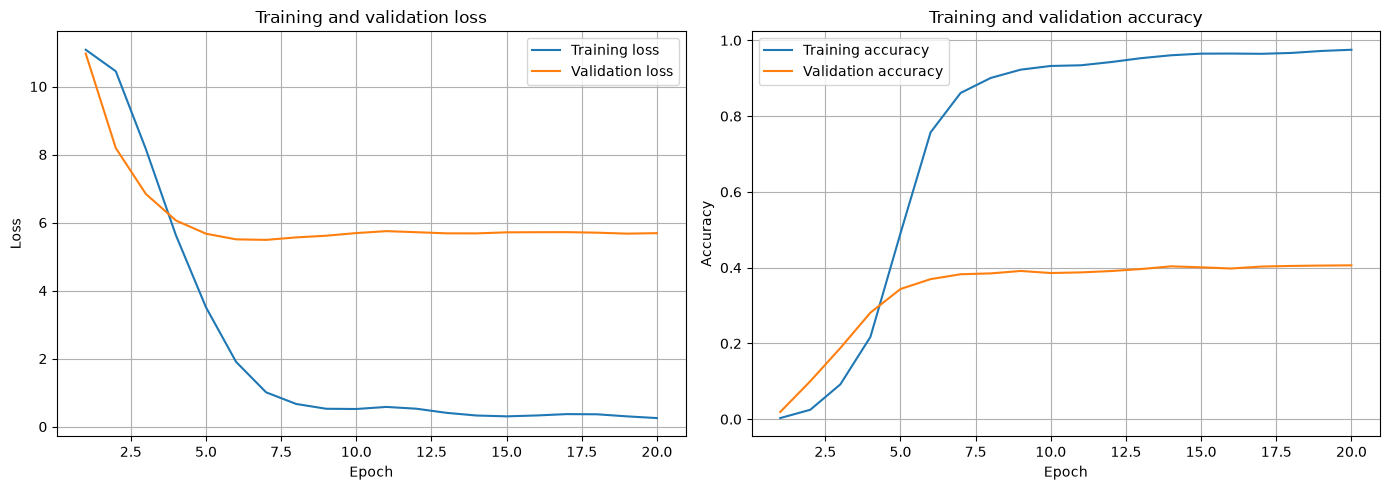

In [20]:

# Cell 20: Plot training curves

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training loss"
)

axes[0].plot(
    history_df["epoch"],
    history_df["validation_loss"],
    label="Validation loss"
)

axes[0].set_title("Training and validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)


axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="Training accuracy"
)

axes[1].plot(
    history_df["epoch"],
    history_df["validation_accuracy"],
    label="Validation accuracy"
)

axes[1].set_title("Training and validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [21]:

# Cell 21: Confirm experiment outputs

expected_outputs = [
    "best_finetuned_dreams.pt",
    "validation_predictions.csv",
    "training_history.csv",
    "metrics.json",
    "training_curves.png"
]

print("Experiment output files:\n")

for filename in expected_outputs:

    path = OUTPUT_DIR / filename

    if path.exists():
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"OK  {filename} ({size_mb:.2f} MB)")
    else:
        print(f"MISSING  {filename}")


Experiment output files:

OK  best_finetuned_dreams.pt (622.88 MB)
OK  validation_predictions.csv (0.58 MB)
OK  training_history.csv (0.00 MB)
OK  metrics.json (0.00 MB)
OK  training_curves.png (0.19 MB)


In [22]:

# Cell 21: Confirm experiment outputs

expected_outputs = [
    "best_finetuned_dreams.pt",
    "validation_predictions.csv",
    "training_history.csv",
    "metrics.json",
    "training_curves.png"
]

print("Experiment output files:\n")

for filename in expected_outputs:

    path = OUTPUT_DIR / filename

    if path.exists():
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"OK  {filename} ({size_mb:.2f} MB)")
    else:
        print(f"MISSING  {filename}")


Experiment output files:

OK  best_finetuned_dreams.pt (622.88 MB)
OK  validation_predictions.csv (0.58 MB)
OK  training_history.csv (0.00 MB)
OK  metrics.json (0.00 MB)
OK  training_curves.png (0.19 MB)
